# 04 · Interactive Demonstration: Forger vs Detective

The detection problem can be framed as the contest at the heart of GANs: a **forger** (the image generator) tries to produce images that pass as real, and a **detective** (the detector) tries to catch them. Each new generator is a better forger. The question this project asks is which detective, a CNN or a Vision Transformer, keeps up better.

Unlike a GAN, the generators studied here (Stable Diffusion 1.4, 2.1 and 3.0) are diffusion models and are never trained against the detector. Each new version is still a stronger forger that the detectives have not seen before.

The application has four parts:

| Tab | What it shows |
|---|---|
| 1 · Can you tell? | The audience and both models judge the same images; a running scoreboard compares them |
| 2 · The forger gets better | Live accuracy of both detectors on fakes from older and newer generators |
| 3 · Blur attack | How each detector's confidence changes as an image is progressively blurred |
| 4 · Explain | Predictions and Grad-CAM heatmaps for any uploaded image |

A static version of the audience challenge is also exported to `outputs/figures/` for use in slides.

In [1]:
# Environment setup
%pip install -q -U timm grad-cam gradio

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import gradio as gr
from PIL import Image
from torchvision.transforms.functional import gaussian_blur
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from google.colab import drive

# Colab's local disk is wiped when the session ends, so all outputs live in Google Drive
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/MAAI901_AIImageDetector")

DATA_DIR = PROJECT_DIR / "outputs" / "data"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
REAL, FAKE = 0, 1                      # FAKE is the positive class (the detection target)
LABEL_NAMES = {REAL: "REAL", FAKE: "FAKE"}
TRAIN_SETUPS = ("trainSD14", "trainSD21")
TEST_SETS = {                          # split name -> generator behind the fake images
    "test_sd14": "SD 1.4",
    "test_sd21": "SD 2.1",
    "test_sd30": "SD 3.0",
    "test_sd21blur": "SD 2.1 blurred",
}

# Two ImageNet-pretrained models of similar size (23.5M vs 21.7M parameters),
# so the comparison isolates architecture rather than capacity.
MODELS = {
    "resnet50": {"timm_id": "resnet50.a1_in1k", "family": "cnn",
                 "display_name": "ResNet-50 (CNN)", "lr": 1e-4, "timm_kwargs": {}},
    "vit_small": {"timm_id": "vit_small_patch16_224.augreg_in21k_ft_in1k", "family": "vit",
                  "display_name": "ViT-S/16 (Transformer)", "lr": 5e-5, "timm_kwargs": {}},
}
INPUT_SIZE = 224                       # resolution both backbones were pretrained at

SHORT = {"resnet50": "CNN", "vit_small": "ViT"}
DISPLAY_SIZE = 160            # 32x32 images are enlarged 5x for viewing only;
                              # larger sizes exaggerate the blur of the low-resolution data

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# One fixed colour per model across every figure
MODEL_COLORS = {"resnet50": "#2a78d6", "vit_small": "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e4df",
    "axes.axisbelow": True, "axes.edgecolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})

GOOD, BAD = "#0ca30c", "#d03b3b"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


In [2]:
class Detector(nn.Module):
    """Pretrained timm backbone with built-in preprocessing.

    Keeping the resize and normalisation inside the model guarantees that
    training, evaluation, Grad-CAM and the demo all preprocess identically.
    """

    def __init__(self, spec, input_size=INPUT_SIZE, pretrained=True):
        super().__init__()
        self.spec = dict(spec)
        self.family = spec["family"]
        self.input_size = input_size
        self.backbone = timm.create_model(spec["timm_id"], pretrained=pretrained,
                                          num_classes=2, **spec["timm_kwargs"])
        cfg = timm.data.resolve_model_data_config(self.backbone)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1), persistent=False)

    def preprocess(self, x):
        """Float NCHW in [0, 1] at any size -> normalised NCHW at input_size."""
        if x.shape[-2:] != (self.input_size, self.input_size):
            # 32x32 -> 224x224 on the GPU; bilinear interpolation adds no new detail
            x = F.interpolate(x, size=(self.input_size, self.input_size),
                              mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std

    def forward(self, x):
        return self.backbone(self.preprocess(x))


def to_float(x_uint8):
    """uint8 NHWC (storage format) -> float NCHW in [0, 1] (model format)."""
    return x_uint8.permute(0, 3, 1, 2).float().div(255.0)

def load_split(name):
    """Return (images uint8 [N, 32, 32, 3], labels int64 [N]) for a saved split."""
    with np.load(DATA_DIR / f"{name}.npz") as z:
        return z["x"], z["y"]

def load_detector(setup, model_key):
    """Rebuild a model from its checkpoint (architecture + fine-tuned weights)."""
    ckpt = torch.load(MODEL_DIR / f"{setup}__{model_key}.pt", map_location="cpu",
                      weights_only=False)
    model = Detector(ckpt["spec"], input_size=ckpt["input_size"], pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval()


@torch.no_grad()
def predict_proba(model, x_uint8, batch_size=512):
    """P(FAKE) for every image, in batches, with mixed precision on GPU."""
    model.eval()
    use_amp = device.type == "cuda"
    out = []
    for i in range(0, len(x_uint8), batch_size):
        xb = to_float(torch.from_numpy(x_uint8[i:i + batch_size]).to(device))
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(xb).float().softmax(1)[:, FAKE].cpu())
    return torch.cat(out).numpy()

def gradcam_layer(model):
    """Last spatial feature layer: final ResNet stage, or the last ViT block."""
    if model.family == "vit":
        return [model.backbone.blocks[-1].norm1]
    return [model.backbone.layer4[-1]]


def vit_reshape(model):
    """ViT outputs a token sequence; Grad-CAM needs a 2D map (14x14 patch grid)."""
    n_prefix = getattr(model.backbone, "num_prefix_tokens", 1)
    gh, gw = model.backbone.patch_embed.grid_size
    def reshape(tokens):
        tokens = tokens[:, n_prefix:, :]             # drop the [CLS] token
        return tokens.reshape(tokens.size(0), gh, gw, tokens.size(2)).permute(0, 3, 1, 2)
    return reshape


def gradcam(model, x_uint8, target_class=None, batch_size=32):
    """Heatmaps [N, 224, 224] in 0..1 and the matching upsampled images [N, 224, 224, 3].

    target_class=None explains whichever class the model predicted.
    """
    reshape = vit_reshape(model) if model.family == "vit" else None
    cams, imgs = [], []
    with GradCAM(model=model, target_layers=gradcam_layer(model),
                 reshape_transform=reshape) as cam:
        for i in range(0, len(x_uint8), batch_size):
            xb = to_float(torch.from_numpy(x_uint8[i:i + batch_size]).to(device))
            xb = F.interpolate(xb, size=(model.input_size, model.input_size),
                               mode="bilinear", align_corners=False)
            targets = (None if target_class is None
                       else [ClassifierOutputTarget(target_class)] * len(xb))
            cams.append(cam(input_tensor=xb, targets=targets))
            imgs.append(xb.permute(0, 2, 3, 1).cpu().numpy())
    return np.concatenate(cams), np.clip(np.concatenate(imgs), 0, 1)


def overlay(img01, cam, alpha=0.45):
    return show_cam_on_image(img01.astype(np.float32), cam, use_rgb=True, image_weight=1 - alpha)


def blur(x, sigma):
    """Gaussian blur on uint8 NHWC images; the kernel covers +/- 3 sigma."""
    if sigma <= 0:
        return x
    k = 2 * int(np.ceil(3 * sigma)) + 1
    t = torch.from_numpy(x).permute(0, 3, 1, 2).float()
    t = gaussian_blur(t, kernel_size=[k, k], sigma=[float(sigma)] * 2)
    return t.round().clamp(0, 255).byte().permute(0, 2, 3, 1).numpy()


def enlarge(img32):
    return Image.fromarray(img32).resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.LANCZOS)


models = {(setup, key): load_detector(setup, key) for setup in TRAIN_SETUPS for key in MODELS}
names = {key: spec["display_name"] for key, spec in MODELS.items()}
test_sets = {name: load_split(name) for name in TEST_SETS}

# Image pools: real photographs are shared by all test sets; fakes come from each generator
x14, y14 = test_sets["test_sd14"]
real_pool = x14[y14 == REAL]
fake_pools = {t: test_sets[t][0][test_sets[t][1] == FAKE] for t in ("test_sd14", "test_sd21", "test_sd30")}
rng = np.random.default_rng()      # unseeded, so every demo session shows new images
print(f"{len(models)} models loaded; {len(real_pool):,} real and "
      f"{sum(len(p) for p in fake_pools.values()):,} AI-generated test images available.")

4 models loaded; 10,000 real and 29,870 AI-generated test images available.


## Audience challenge (static version for slides)

Six test images, three real and three AI-generated, shown first without labels and then with the answers and both detectors' verdicts. Detectors trained on SD 1.4 images are used.

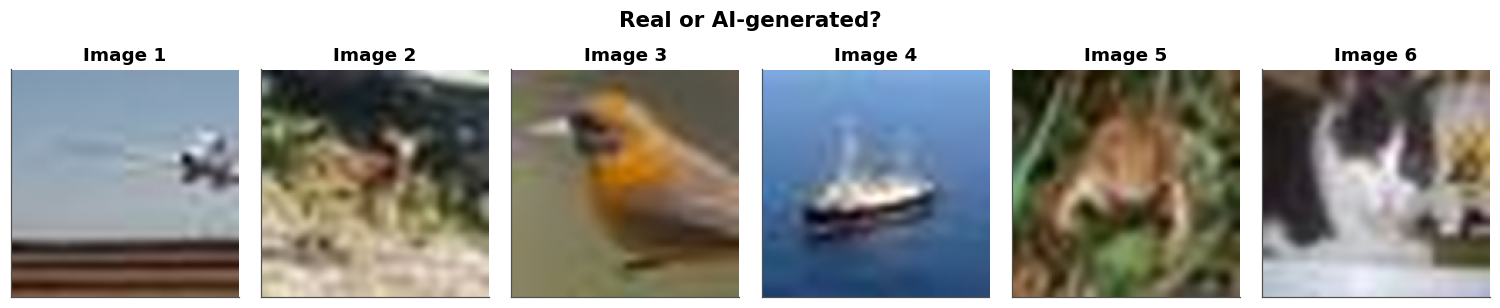

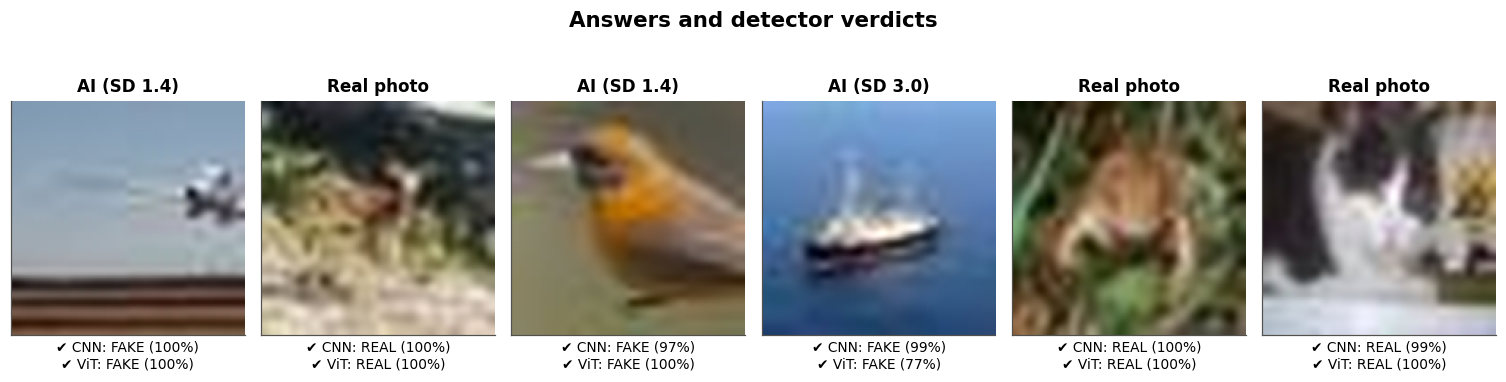

In [3]:
fig_rng = np.random.default_rng(SEED)
labels = fig_rng.permutation([REAL] * 3 + [FAKE] * 3)
images, sources = [], []
for lab in labels:
    if lab == REAL:
        images.append(real_pool[fig_rng.integers(len(real_pool))])
        sources.append("Real photo")
    else:
        t = list(fake_pools)[fig_rng.integers(len(fake_pools))]
        images.append(fake_pools[t][fig_rng.integers(len(fake_pools[t]))])
        sources.append(f"AI ({TEST_SETS[t]})")
images = np.stack(images)
p_fake = {k: predict_proba(models[("trainSD14", k)], images) for k in MODELS}

for reveal in (False, True):
    fig, axes = plt.subplots(1, len(images), figsize=(2.3 * len(images), 3.3 if reveal else 2.7))
    for j, ax in enumerate(axes):
        ax.imshow(enlarge(images[j]))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if not reveal:
            ax.set_title(f"Image {j + 1}", fontsize=12, fontweight="bold")
            continue
        truth = LABEL_NAMES[labels[j]]
        ax.set_title(sources[j], fontsize=11, fontweight="bold")
        verdicts = []
        for k in MODELS:
            pred = "FAKE" if p_fake[k][j] >= 0.5 else "REAL"
            mark = "\u2714" if pred == truth else "\u2718"
            verdicts.append(f"{mark} {SHORT[k]}: {pred} ({max(p_fake[k][j], 1 - p_fake[k][j]):.0%})")
        ax.set_xlabel("\n".join(verdicts), fontsize=9)
    fig.suptitle("Real or AI-generated?" if not reveal else "Answers and detector verdicts",
                 fontsize=14, fontweight="bold", y=1.02)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"04_challenge_{'answers' if reveal else 'question'}.png")
    plt.show()

## Interactive application

**Tab 1** draws a random mix of real photographs and fakes from all three generators, then reveals the answers with each detector's verdict and keeps score across rounds.

**Tab 2** samples fresh, class-balanced test images and measures both detectors live. Detectors trained on SD 1.4 show how they cope with newer generators.

**Tab 3** uses the detectors trained on SD 2.1, matching the blur experiment in notebook 03, and plots P(fake) against blur strength for a single image.

**Tab 4** accepts any image. Uploads are centre-cropped and reduced to 32x32 before classification, which is the main limitation of the system for real-world photographs.

In [4]:
N_SLOTS = 4
SETUP_NAMES = {"trainSD14": "SD 1.4", "trainSD21": "SD 2.1"}
CHALLENGE_SETUP, BLUR_SETUP, EXPLAIN_SETUP = "trainSD14", "trainSD21", "trainSD14"
BLUR_LEVELS = np.round(np.arange(0, 3.01, 0.25), 2)
INITIAL_STATE = {"items": [], "revealed": True,
                 "score": {"Audience": [0, 0], "CNN": [0, 0], "ViT": [0, 0]}}
DISCLAIMER = ("Research prototype. Images are reduced to 32x32 pixels, as in the training data, so "
              "predictions on real-world photographs are unreliable and must never be used to "
              "accuse anyone of faking an image.")


# ---------------------------------------------------------------- tab 1: challenge
def draw_challenge():
    """A shuffled round of N_SLOTS images containing at least one real and one fake."""
    labels = [REAL, FAKE] + [int(v) for v in rng.integers(0, 2, N_SLOTS - 2)]
    rng.shuffle(labels)
    items = []
    for lab in labels:
        if lab == REAL:
            items.append({"img": real_pool[rng.integers(len(real_pool))], "label": REAL,
                          "source": "Real photograph (CIFAR-10)"})
        else:
            t = list(fake_pools)[rng.integers(len(fake_pools))]
            items.append({"img": fake_pools[t][rng.integers(len(fake_pools[t]))], "label": FAKE,
                          "source": f"AI-generated ({TEST_SETS[t]})"})
    return items


def scoreboard(state):
    cards = []
    for who, (correct, total) in state["score"].items():
        pct = f"{correct / total:.0%}" if total else "\u2013"
        cards.append(f"<div style='flex:1;padding:14px;border-radius:10px;border:1px solid #8884;"
                     f"text-align:center'><div style='font-size:15px;opacity:.75'>{who}</div>"
                     f"<div style='font-size:30px;font-weight:700'>{pct}</div>"
                     f"<div style='opacity:.75'>{correct} / {total} correct</div></div>")
    return "<div style='display:flex;gap:12px'>" + "".join(cards) + "</div>"


def cell(text, correct):
    mark = "\u2714" if correct else "\u2718"
    return f"<td style='color:{GOOD if correct else BAD};font-weight:600'>{mark} {text}</td>"


def new_round(state):
    items = draw_challenge()
    state = {**state, "items": items, "revealed": False}
    return [enlarge(it["img"]) for it in items] + [None] * N_SLOTS + [state, "", scoreboard(state)]


def reveal(state, *votes):
    items = state["items"]
    if not items:
        return "<p>Start a round first.</p>", state, scoreboard(state)
    x = np.stack([it["img"] for it in items])
    p = {k: predict_proba(models[(CHALLENGE_SETUP, k)], x) for k in MODELS}
    score = {who: list(v) for who, v in state["score"].items()}
    count = not state["revealed"]                       # a round is only scored once
    rows = []
    for j, it in enumerate(items):
        truth = LABEL_NAMES[it["label"]]
        cells = [f"<td><b>Image {j + 1}</b></td>",
                 f"<td><b>{truth}</b><br><small>{it['source']}</small></td>"]
        if votes[j]:
            ok = votes[j] == truth
            cells.append(cell(votes[j], ok))
            if count:
                score["Audience"][0] += ok
                score["Audience"][1] += 1
        else:
            cells.append("<td>\u2013</td>")
        for k in MODELS:
            pred = "FAKE" if p[k][j] >= 0.5 else "REAL"
            ok = pred == truth
            cells.append(cell(f"{pred} ({max(p[k][j], 1 - p[k][j]):.0%})", ok))
            if count:
                score[SHORT[k]][0] += ok
                score[SHORT[k]][1] += 1
        rows.append("<tr>" + "".join(cells) + "</tr>")
    header = ("<tr><th></th><th>Truth</th><th>Audience</th>"
              + "".join(f"<th>{names[k]}</th>" for k in MODELS) + "</tr>")
    table = ("<table style='width:100%;font-size:16px;border-collapse:collapse' cellpadding='8'>"
             + header + "".join(rows) + "</table>")
    state = {**state, "score": score, "revealed": True}
    return table, state, scoreboard(state)


# ---------------------------------------------------------------- tab 2: generator shift
def live_benchmark(setup, n_per_set):
    """Accuracy of both detectors on freshly sampled, class-balanced images from every test set."""
    acc = {k: [] for k in MODELS}
    for t, (x, y) in test_sets.items():
        idx = np.concatenate([rng.choice(np.where(y == lab)[0], min(int(n_per_set) // 2, (y == lab).sum()),
                                         replace=False) for lab in (REAL, FAKE)])
        for k in MODELS:
            acc[k].append(((predict_proba(models[(setup, k)], x[idx]) >= 0.5) == y[idx]).mean() * 100)
    fig = Figure(figsize=(9, 4.2))
    ax = fig.subplots()
    width = 0.38
    for i, k in enumerate(MODELS):
        xs = np.arange(len(TEST_SETS)) + (i - 0.5) * width
        bars = ax.bar(xs, acc[k], width * 0.92, color=MODEL_COLORS[k], label=names[k])
        ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=10)
    ax.axhline(50, color=MUTED, ls=":", lw=1)
    ax.text(len(TEST_SETS) - 0.5, 51.5, "coin flip", color=MUTED, ha="right", fontsize=9)
    ax.set_xticks(range(len(TEST_SETS)), [f"{TEST_SETS[t]} fakes" for t in TEST_SETS])
    ax.set(ylim=(40, 105), ylabel="accuracy (%)",
           title=f"Detectors trained on {SETUP_NAMES[setup]} fakes, "
                 f"tested on {int(n_per_set):,} images per generator")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------- tab 3: blur attack
def pick(kind):
    pool = fake_pools["test_sd21"] if kind == "fake" else real_pool
    return pool[rng.integers(len(pool))]


def blur_attack(img, sigma):
    if img is None:
        return [None] * (len(MODELS) + 2)
    curve = {k: predict_proba(models[(BLUR_SETUP, k)],
                              np.concatenate([blur(img[None], s) for s in BLUR_LEVELS])) for k in MODELS}
    current = int(np.argmin(np.abs(BLUR_LEVELS - sigma)))
    verdicts = [{"FAKE": float(curve[k][current]), "REAL": float(1 - curve[k][current])} for k in MODELS]
    fig = Figure(figsize=(7, 3.2))
    ax = fig.subplots()
    for k in MODELS:
        ax.plot(BLUR_LEVELS, curve[k], "-o", color=MODEL_COLORS[k], label=names[k], markersize=5)
    ax.axhline(0.5, color=MUTED, ls=":", lw=1)
    ax.text(BLUR_LEVELS[-1], 0.52, "decision threshold", color=MUTED, ha="right", fontsize=8)
    ax.axvline(BLUR_LEVELS[current], color=INK, lw=1, alpha=0.4)
    ax.set(ylim=(-0.03, 1.03), xlabel="blur strength (Gaussian sigma, pixels)", ylabel="P(fake)",
           title="Detector confidence as the image is blurred")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return [enlarge(blur(img[None], BLUR_LEVELS[current])[0])] + verdicts + [fig]


def load_for_blur(kind, sigma):
    img = pick(kind)
    return [img, enlarge(img)] + blur_attack(img, sigma)


# ---------------------------------------------------------------- tab 4: explain
def to_model_input(img):
    """Centre-crop to a square and resize to 32x32 (bilinear, as in the dataset)."""
    img = img.convert("RGB")
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))
    return np.array(img.resize((32, 32), Image.BILINEAR), dtype=np.uint8)[None]


def explain(img, exact):
    # Test images are analysed from their exact pixels; uploads are converted to 32x32
    if exact is not None:
        x = np.asarray(exact, dtype=np.uint8)[None]
    elif img is not None:
        x = to_model_input(img)
    else:
        return [None] * len(MODELS) + [[], None]
    verdicts, gallery = [], []
    for k in MODELS:
        model = models[(EXPLAIN_SETUP, k)]
        p = float(predict_proba(model, x)[0])
        pred = int(p >= 0.5)
        verdicts.append({"FAKE": p, "REAL": 1 - p})
        cams, imgs = gradcam(model, x, target_class=pred)
        gallery.append((overlay(imgs[0], cams[0]),
                        f"{names[k]}: {LABEL_NAMES[pred]} ({max(p, 1 - p):.0%})"))
    return verdicts + [gallery, Image.fromarray(x[0]).resize((224, 224), Image.NEAREST)]


def random_example():
    if rng.random() < 0.5:
        img, caption = real_pool[rng.integers(len(real_pool))], "REAL (CIFAR-10 photograph)"
    else:
        t = list(fake_pools)[rng.integers(len(fake_pools))]
        img, caption = fake_pools[t][rng.integers(len(fake_pools[t]))], f"FAKE ({TEST_SETS[t]})"
    return enlarge(img), caption, img


# ---------------------------------------------------------------- layout
with gr.Blocks(title="Forger vs Detective") as app:
    gr.Markdown("# Forger vs Detective: can AI catch AI-generated images?\n"
                f"Comparing a CNN (ResNet-50) and a Vision Transformer (ViT-S/16).  \n*{DISCLAIMER}*")

    with gr.Tab("1 \u00b7 Can you tell?"):
        state = gr.State(INITIAL_STATE)
        gr.Markdown("Some of these images are real photographs and some were generated by AI. "
                    "Which are which?")
        slots, votes = [], []
        with gr.Row():
            for j in range(N_SLOTS):
                with gr.Column(min_width=180):
                    slots.append(gr.Image(label=f"Image {j + 1}", interactive=False,
                                          height=DISPLAY_SIZE, width=DISPLAY_SIZE))
                    votes.append(gr.Radio(["REAL", "FAKE"], label="Audience vote"))
        with gr.Row():
            new_btn = gr.Button("New round", variant="primary")
            reveal_btn = gr.Button("Reveal answers")
        result = gr.HTML()
        board = gr.HTML(scoreboard(INITIAL_STATE))
        new_btn.click(new_round, inputs=state, outputs=slots + votes + [state, result, board])
        reveal_btn.click(reveal, inputs=[state] + votes, outputs=[result, state, board])

    with gr.Tab("2 \u00b7 The forger gets better"):
        gr.Markdown("The detectives learn from one forger. How do they cope when a newer, "
                    "better forger appears?")
        with gr.Row():
            setup_choice = gr.Radio([("SD 1.4 fakes", "trainSD14"), ("SD 2.1 fakes", "trainSD21")],
                                    value="trainSD14", label="Detectors trained on")
            n_choice = gr.Slider(200, 4000, value=1000, step=200, label="Test images per generator")
        bench_btn = gr.Button("Run live test", variant="primary")
        bench_plot = gr.Plot()
        bench_btn.click(live_benchmark, inputs=[setup_choice, n_choice], outputs=bench_plot)

    with gr.Tab("3 \u00b7 Blur attack"):
        gr.Markdown("A simple blur can hide a forger's fingerprints. Drag the slider and watch "
                    "each detector's confidence (detectors trained on SD 2.1 fakes).")
        blur_img = gr.State(None)
        with gr.Row():
            fake_btn = gr.Button("Random AI image (SD 2.1)", variant="primary")
            real_btn = gr.Button("Random real photograph")
        with gr.Row():
            original_view = gr.Image(label="Original", interactive=False, height=DISPLAY_SIZE, width=DISPLAY_SIZE)
            blurred_view = gr.Image(label="What the detectors see", interactive=False,
                                    height=DISPLAY_SIZE, width=DISPLAY_SIZE)
            with gr.Column():
                blur_labels = [gr.Label(num_top_classes=2, label=names[k]) for k in MODELS]
        sigma = gr.Slider(0, 3, value=0, step=0.25, label="Blur strength (Gaussian sigma, pixels)")
        blur_plot = gr.Plot()
        blur_outputs = [blurred_view] + blur_labels + [blur_plot]
        fake_btn.click(lambda s: load_for_blur("fake", s), inputs=sigma,
                       outputs=[blur_img, original_view] + blur_outputs)
        real_btn.click(lambda s: load_for_blur("real", s), inputs=sigma,
                       outputs=[blur_img, original_view] + blur_outputs)
        sigma.release(blur_attack, inputs=[blur_img, sigma], outputs=blur_outputs)

    with gr.Tab("4 \u00b7 Explain"):
        gr.Markdown("Upload any image, or draw a test image with a known answer. Grad-CAM shows "
                    "the regions each detector relied on.")
        exact = gr.State(None)
        with gr.Row():
            with gr.Column(scale=1):
                upload = gr.Image(type="pil", label="Image")
                truth = gr.Textbox(label="True label (test images only)", interactive=False)
                with gr.Row():
                    example_btn = gr.Button("Random test image")
                    explain_btn = gr.Button("Analyse", variant="primary")
                model_view = gr.Image(label="Model input (32x32)", interactive=False)
            with gr.Column(scale=2):
                explain_labels = [gr.Label(num_top_classes=2, label=names[k]) for k in MODELS]
                cams = gr.Gallery(label="Grad-CAM", columns=len(MODELS), height=300)
        explain_outputs = explain_labels + [cams, model_view]
        example_btn.click(random_example, outputs=[upload, truth, exact]) \
                   .then(explain, inputs=[upload, exact], outputs=explain_outputs)
        explain_btn.click(explain, inputs=[upload, exact], outputs=explain_outputs)
        upload.upload(lambda: ("", None), outputs=[truth, exact])

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://eb47933af472323b2a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
